# 02 — Baseline CNN (dilatih dari nol)

Model sederhana yang dilatih **tanpa** bobot pretrained. Fungsinya sebagai **pembanding**:
nanti di notebook 03, transfer learning (ResNet / EfficientNet) harus terbukti lebih baik dari angka di sini.

Isi notebook:
1. Memuat `splits.csv` hasil notebook 01 (train / val / test yang sudah bersih dari duplikat).
2. Augmentasi gambar dan *weighted loss* untuk kelas yang lebih sedikit.
3. Training dengan *early stopping* berdasarkan **macro F1** di data validasi.
4. Evaluasi di data test: accuracy, macro F1, recall per kelas, confusion matrix, contoh salah prediksi.

**Rekomendasi:** jalankan dengan GPU Colab (di VS Code: *Select Kernel → Colab → GPU*).
Di laptop tanpa GPU, set `QUICK = True` dulu untuk memastikan kode jalan (±5–10 menit).

## 1. Konfigurasi

In [3]:
import sys, os, json, time, zipfile, platform
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

EXPERIMENT = "baseline_cnn"
IMG_SIZE   = 224
BATCH_SIZE = 32
EPOCHS     = 25
LR         = 1e-3
PATIENCE   = 5        # berhenti bila macro F1 validasi tidak naik selama 5 epoch
SEED       = 42
QUICK      = False    # True = 20% data & 3 epoch, untuk cek kode di laptop

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/dokter-tani")
    DATA_DIR   = Path("/content/data/raw/chilli_leaf")
    if not DATA_DIR.exists():
        print("Mengekstrak dataset dari Drive (sekali per sesi)...")
        with zipfile.ZipFile(DRIVE_ROOT / "chilli_leaf.zip") as z:
            z.extractall(DATA_DIR)
    SPLITS_CSV = DRIVE_ROOT / "splits.csv"
    OUT_DIR    = DRIVE_ROOT / "reports" / "models" / EXPERIMENT
    CKPT_DIR   = DRIVE_ROOT / "checkpoints"
else:
    DATA_DIR   = PROJECT_ROOT / "data" / "raw" / "chilli_leaf"
    SPLITS_CSV = PROJECT_ROOT / "data" / "splits.csv"
    OUT_DIR    = PROJECT_ROOT / "reports" / "models" / EXPERIMENT
    CKPT_DIR   = PROJECT_ROOT / "checkpoints"

if QUICK:
    EPOCHS = 3

OUT_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)
print("Berjalan di:", "Colab" if IN_COLAB else "laptop", "| QUICK:", QUICK)
print("Dataset   :", DATA_DIR, "| ada:", DATA_DIR.exists())
print("splits.csv:", SPLITS_CSV, "| ada:", SPLITS_CSV.exists())
assert DATA_DIR.exists() and SPLITS_CSV.exists(), "Dataset atau splits.csv belum ada. Jalankan notebook 01 dulu."

Berjalan di: laptop | QUICK: False
Dataset   : c:\laragon\www\final-project\dokter-tani\data\raw\chilli_leaf | ada: True
splits.csv: c:\laragon\www\final-project\dokter-tani\data\splits.csv | ada: True


In [4]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(SEED)

if torch.cuda.is_available():
    DEVICE = "cuda"
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    DEVICE = "mps"    # Mac dengan chip Apple
else:
    DEVICE = "cpu"
NUM_WORKERS = 2 if IN_COLAB else 0   # 0 = aman untuk Windows/Jupyter di laptop
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

INK, MUTED, GRID = "#18241B", "#5B6660", "#E3E6DC"
SERIES = ["#2a78d6", "#eb6834"]   # biru = train, oranye = validasi
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})

Device: cpu 


## 2. Data
Path di `splits.csv` dinormalisasi ke garis miring `/`, supaya file yang dibuat di Windows tetap terbaca di Colab (Linux).

In [5]:
splits = pd.read_csv(SPLITS_CSV)
splits["rel_path"] = splits["rel_path"].str.replace("\\", "/", regex=False)

missing = [p for p in splits["rel_path"] if not (DATA_DIR / p).exists()]
print(f"File di splits.csv: {len(splits):,} | tidak ditemukan: {len(missing):,}")
if missing:
    print("Contoh yang hilang:", missing[:3])
    raise FileNotFoundError("Struktur folder dataset berbeda dengan saat EDA. Pastikan isi zip = isi folder chilli_leaf.")

if QUICK:
    splits = splits.groupby(["split", "label"]).sample(frac=0.2, random_state=SEED)

CLASSES = sorted(splits["label"].unique())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)

tbl = pd.crosstab(splits["label"], splits["split"])[["train", "val", "test"]]
tbl.loc["TOTAL"] = tbl.sum()
tbl

File di splits.csv: 7,936 | tidak ditemukan: 0


split,train,val,test
label,,,
Bacterial_Spot,878,217,185
Cercospora_Leaf_Spot,1177,252,254
Curl_Virus,1110,237,235
Healthy_Leaf,1037,223,221
Nutrition_Deficiency,746,161,160
Powdery_Mildew,591,126,126
TOTAL,5539,1216,1181


## 3. Augmentasi
Augmentasi hanya untuk data **train**: meniru variasi foto HP di lapangan (posisi, cahaya, sedikit buram). Data val/test hanya di-resize.

In [6]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # standar ImageNet, dipakai juga di notebook 03

train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2, hue=0.02),
    transforms.RandomApply([transforms.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class LeafDataset(Dataset):
    def __init__(self, frame, tfm):
        self.paths = [DATA_DIR / p for p in frame["rel_path"]]
        self.targets = frame["label"].map(CLASS_TO_IDX).to_numpy()
        self.tfm = tfm
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            img = ImageOps.exif_transpose(im).convert("RGB")
        return self.tfm(img), int(self.targets[i])

df_train = splits[splits["split"] == "train"].reset_index(drop=True)
df_val   = splits[splits["split"] == "val"].reset_index(drop=True)
df_test  = splits[splits["split"] == "test"].reset_index(drop=True)

pin = DEVICE == "cuda"
train_dl = DataLoader(LeafDataset(df_train, train_tfms), batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=pin)
val_dl   = DataLoader(LeafDataset(df_val,   eval_tfms),  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
test_dl  = DataLoader(LeafDataset(df_test,  eval_tfms),  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
print(f"Batch per epoch: train {len(train_dl)} | val {len(val_dl)} | test {len(test_dl)}")

Batch per epoch: train 174 | val 38 | test 37


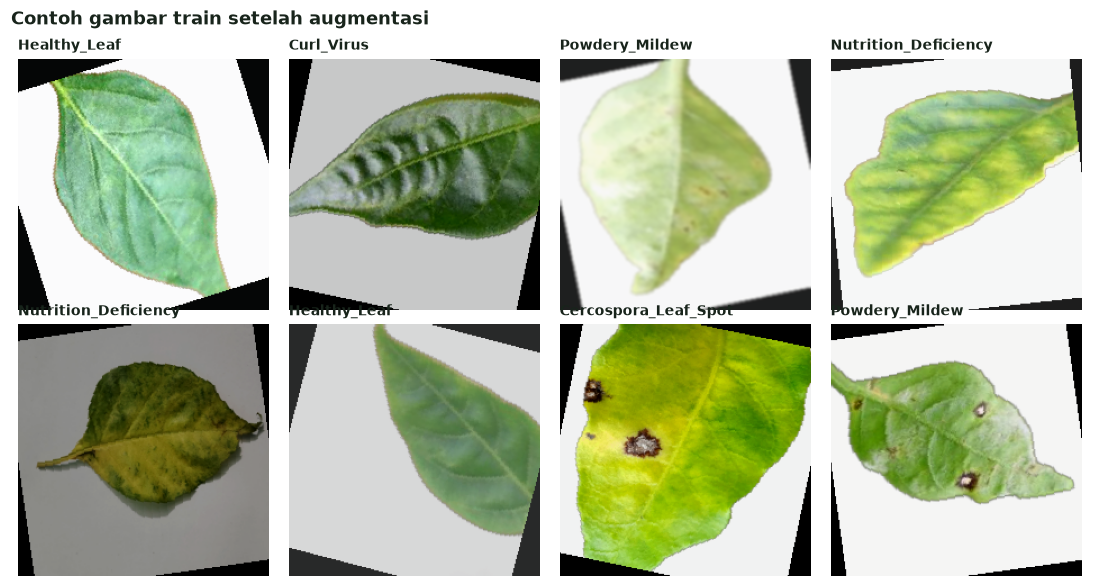

In [7]:
# Cek visual: seperti apa gambar setelah augmentasi?
def denorm(t):
    return (t.permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)

xb, yb = next(iter(train_dl))
n = min(8, len(xb))
fig, axes = plt.subplots(2, 4, figsize=(10, 5.4))
for ax, i in zip(axes.flat, range(8)):
    ax.axis("off")
    if i < n:
        ax.imshow(denorm(xb[i])); ax.set_title(CLASSES[yb[i]], fontsize=9, color=INK, loc="left")
fig.suptitle("Contoh gambar train setelah augmentasi", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout(); fig.savefig(OUT_DIR / "augmentasi_contoh.png"); plt.show()

## 4. Model baseline
Empat blok konvolusi (Conv → BatchNorm → ReLU → MaxPool), lalu *global average pooling* dan satu lapisan klasifikasi.

In [8]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )

class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(conv_block(3, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 256))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, num_classes))
    def forward(self, x):
        return self.head(self.pool(self.features(x)))

model = SimpleCNN(NUM_CLASSES).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"Jumlah parameter: {n_params:,}")

Jumlah parameter: 1,174,758


## 5. Training
*Weighted loss*: kelas yang fotonya lebih sedikit diberi bobot lebih besar, supaya model tidak mengabaikannya. Model terbaik dipilih berdasarkan **macro F1** validasi (rata-rata F1 semua kelas, adil untuk kelas kecil).

In [9]:
counts = df_train["label"].value_counts().reindex(CLASSES).to_numpy()
class_weights = torch.tensor(counts.sum() / (NUM_CLASSES * counts), dtype=torch.float32, device=DEVICE)
print("Bobot kelas:", {c: round(float(w), 2) for c, w in zip(CLASSES, class_weights.cpu())})

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.3, patience=2)
use_amp = DEVICE == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def run_epoch(model, loader, train):
    model.train(train)
    total_loss, y_true, y_pred = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in tqdm(loader, leave=False, desc="train" if train else "eval"):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type="cuda", enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer); scaler.update()
            total_loss += loss.item() * len(y)
            y_true += y.tolist(); y_pred += logits.argmax(1).tolist()
    return total_loss / len(loader.dataset), np.array(y_true), np.array(y_pred)

Bobot kelas: {'Bacterial_Spot': 1.05, 'Cercospora_Leaf_Spot': 0.78, 'Curl_Virus': 0.83, 'Healthy_Leaf': 0.89, 'Nutrition_Deficiency': 1.24, 'Powdery_Mildew': 1.56}


In [ ]:
CKPT_PATH = CKPT_DIR / f"{EXPERIMENT}.pt"
history, best_f1, bad_epochs = [], -1.0, 0
t_start = time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_y, tr_p = run_epoch(model, train_dl, train=True)
    va_loss, va_y, va_p = run_epoch(model, val_dl, train=False)
    va_f1, va_acc = f1_score(va_y, va_p, average="macro"), accuracy_score(va_y, va_p)
    scheduler.step(va_f1)
    history.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss,
                        train_acc=accuracy_score(tr_y, tr_p), val_acc=va_acc, val_f1=va_f1,
                        lr=optimizer.param_groups[0]["lr"], seconds=time.time() - t0))
    improved = va_f1 > best_f1
    if improved:
        best_f1, bad_epochs = va_f1, 0
        torch.save({"model": model.state_dict(), "classes": CLASSES, "img_size": IMG_SIZE,
                    "mean": MEAN, "std": STD, "epoch": epoch, "val_f1": va_f1}, CKPT_PATH)
    else:
        bad_epochs += 1
    print(f"Epoch {epoch:2d} | loss {tr_loss:.3f} / {va_loss:.3f} | val acc {va_acc:.3f} | "
          f"val F1 {va_f1:.3f} {'★ disimpan' if improved else ''} | {time.time() - t0:.0f} dtk")
    if bad_epochs >= PATIENCE:
        print(f"Early stopping: F1 validasi tidak naik selama {PATIENCE} epoch.")
        break

hist = pd.DataFrame(history)
hist.to_csv(OUT_DIR / "history.csv", index=False)
print(f"\nSelesai dalam {(time.time() - t_start) / 60:.1f} menit | F1 validasi terbaik: {best_f1:.3f}")

Epoch  1 | loss 1.113 / 0.890 | val acc 0.643 | val F1 0.663 ★ disimpan | 900 dtk


Epoch  2 | loss 0.831 / 0.770 | val acc 0.700 | val F1 0.715 ★ disimpan | 890 dtk


Epoch  3 | loss 0.722 / 0.949 | val acc 0.590 | val F1 0.565  | 870 dtk


Epoch  4 | loss 0.670 / 0.756 | val acc 0.678 | val F1 0.677  | 848 dtk


Epoch  5 | loss 0.556 / 0.581 | val acc 0.805 | val F1 0.807 ★ disimpan | 838 dtk


...

Epoch 21 | loss 0.193 / 0.176 | val acc 0.944 | val F1 0.947  | 845 dtk


Epoch 22 | loss 0.183 / 0.182 | val acc 0.945 | val F1 0.948  | 859 dtk


Epoch 23 | loss 0.188 / 0.165 | val acc 0.943 | val F1 0.947  | 821 dtk


Epoch 24 | loss 0.175 / 0.133 | val acc 0.959 | val F1 0.962 ★ disimpan | 826 dtk


Epoch 25 | loss 0.181 / 0.146 | val acc 0.942 | val F1 0.946  | 840 dtk

Selesai dalam 361.9 menit | F1 validasi terbaik: 0.962


### Kurva belajar
Kalau loss train terus turun tetapi loss validasi naik, model mulai **overfitting**.

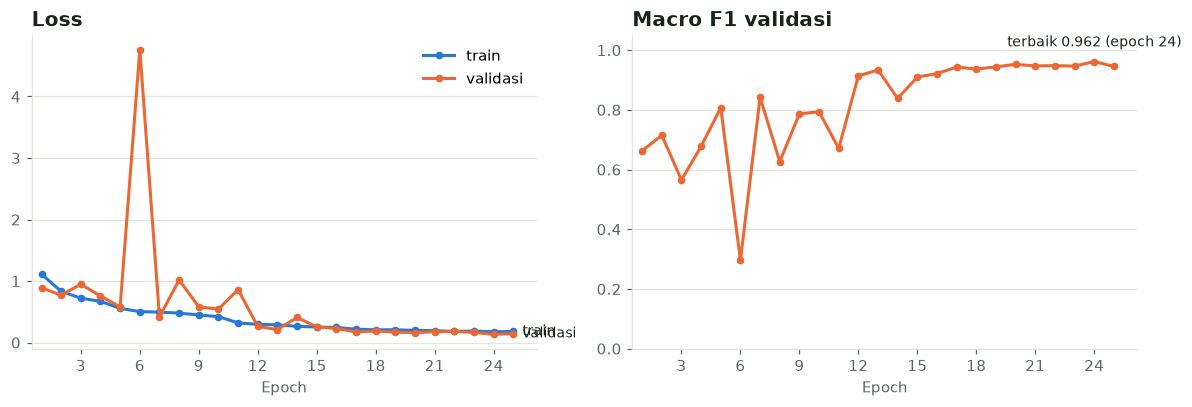

In [11]:
from matplotlib.ticker import MaxNLocator

def end_label(ax, x, y, text):
    ax.annotate(text, (x, y), xytext=(6, 0), textcoords="offset points", va="center", color=INK, fontsize=9)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for col, name, c in [("train_loss", "train", SERIES[0]), ("val_loss", "validasi", SERIES[1])]:
    a1.plot(hist["epoch"], hist[col], color=c, linewidth=2, marker="o", markersize=4, label=name)
    end_label(a1, hist["epoch"].iloc[-1], hist[col].iloc[-1], name)
a1.set_title("Loss"); a1.set_xlabel("Epoch"); a1.legend(frameon=False, loc="upper right")
a2.plot(hist["epoch"], hist["val_f1"], color=SERIES[1], linewidth=2, marker="o", markersize=4)
best = hist.loc[hist["val_f1"].idxmax()]
a2.annotate(f"terbaik {best.val_f1:.3f} (epoch {int(best.epoch)})", (best.epoch, best.val_f1),
            xytext=(0, 10), textcoords="offset points", ha="center", color=INK, fontsize=9)
a2.set_title("Macro F1 validasi"); a2.set_xlabel("Epoch"); a2.set_ylim(0, 1.05)
for ax in (a1, a2):
    ax.yaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    ax.set_xlim(0.5, hist["epoch"].max() + 1.2)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.tight_layout(); fig.savefig(OUT_DIR / "kurva_belajar.png"); plt.show()

## 6. Evaluasi di data test
Data test **tidak pernah** dilihat saat training atau memilih model, jadi angka di sini yang dilaporkan di presentasi.

In [12]:
ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
model.load_state_dict(ckpt["model"]); model.eval()

probs, y_true = [], []
with torch.no_grad():
    for x, y in tqdm(test_dl, leave=False, desc="test"):
        probs.append(torch.softmax(model(x.to(DEVICE)), 1).cpu()); y_true += y.tolist()
probs = torch.cat(probs).numpy(); y_true = np.array(y_true); y_pred = probs.argmax(1)

test_acc = accuracy_score(y_true, y_pred)
test_f1 = f1_score(y_true, y_pred, average="macro")
report = classification_report(y_true, y_pred, labels=range(NUM_CLASSES), target_names=CLASSES,
                               output_dict=True, zero_division=0)
per_class = (pd.DataFrame(report).T.loc[CLASSES, ["precision", "recall", "f1-score", "support"]]
               .rename(columns={"f1-score": "f1"}).round(3).astype({"support": int})
               .sort_values("recall"))
print(f"TEST — accuracy: {test_acc:.3f} | macro F1: {test_f1:.3f}")
per_class

TEST — accuracy: 0.966 | macro F1: 0.968


,precision,recall,f1,support
Cercospora_Leaf_Spot,0.996,0.921,0.957,254
Nutrition_Deficiency,0.968,0.956,0.962,160
Bacterial_Spot,0.978,0.973,0.976,185
Curl_Virus,0.942,0.974,0.958,235
Healthy_Leaf,0.944,0.991,0.967,221
Powdery_Mildew,0.977,1.000,0.988,126


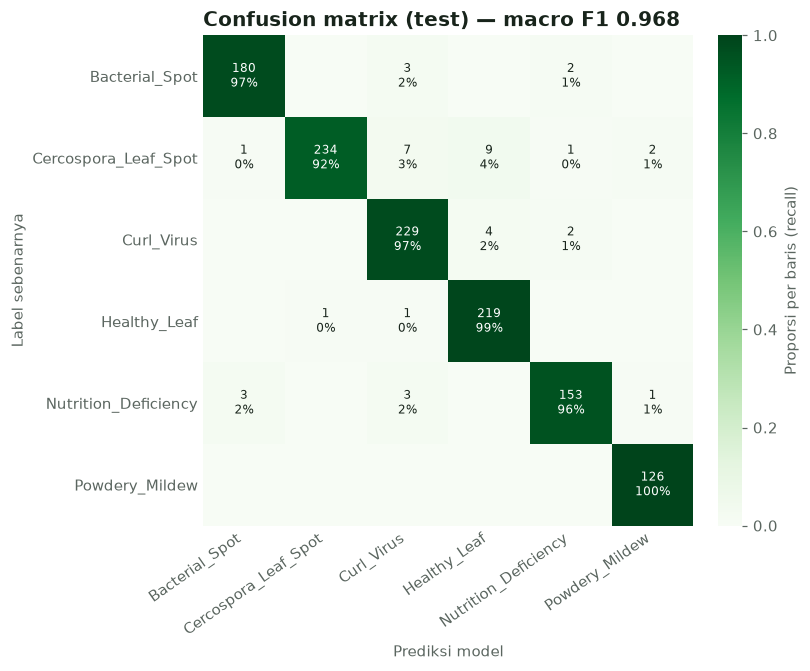

Paling sering tertukar:
  Cercospora_Leaf_Spot → diprediksi Healthy_Leaf: 9 foto
  Cercospora_Leaf_Spot → diprediksi Curl_Virus: 7 foto
  Curl_Virus → diprediksi Healthy_Leaf: 4 foto


In [13]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
cm_pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(cm_pct, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES), CLASSES, rotation=35, ha="right")
ax.set_yticks(range(NUM_CLASSES), CLASSES)
ax.set_xlabel("Prediksi model"); ax.set_ylabel("Label sebenarnya")
ax.set_title(f"Confusion matrix (test) — macro F1 {test_f1:.3f}")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm[i, j]:
            ax.text(j, i, f"{cm[i, j]}\n{cm_pct[i, j]:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if cm_pct[i, j] > 0.55 else INK)
ax.spines[:].set_visible(False); ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.set_label("Proporsi per baris (recall)", color=MUTED)
cb.outline.set_visible(False)
fig.tight_layout(); fig.savefig(OUT_DIR / "confusion_matrix.png"); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], CLASSES[i], CLASSES[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if off[i, j]), reverse=True)[:3]
print("Paling sering tertukar:")
for n, a, b in pairs:
    print(f"  {a} → diprediksi {b}: {n} foto")

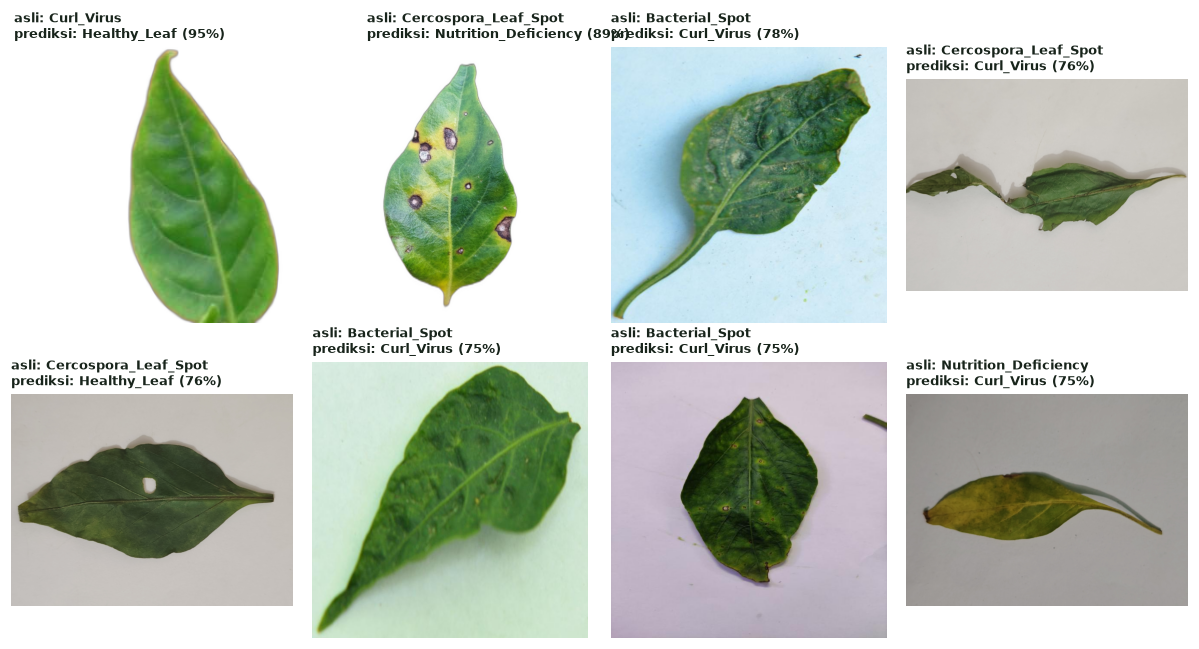

In [14]:
# Contoh salah prediksi dengan keyakinan paling tinggi: bahan diskusi di slide Challenges
wrong = np.where(y_pred != y_true)[0]
wrong = wrong[np.argsort(-probs[wrong].max(1))][:8]
if len(wrong):
    fig, axes = plt.subplots(2, 4, figsize=(11, 6))
    for ax in axes.flat: ax.axis("off")
    for ax, i in zip(axes.flat, wrong):
        with Image.open(DATA_DIR / df_test.loc[i, "rel_path"]) as im:
            ax.imshow(ImageOps.exif_transpose(im).convert("RGB"))
        ax.set_title(f"asli: {CLASSES[y_true[i]]}\nprediksi: {CLASSES[y_pred[i]]} ({probs[i].max():.0%})",
                     fontsize=8.5, color=INK, loc="left")
    fig.tight_layout(); fig.savefig(OUT_DIR / "contoh_salah_prediksi.png"); plt.show()
else:
    print("Tidak ada salah prediksi di data test.")

## 7. Simpan hasil

In [15]:
metrics = {
    "experiment": EXPERIMENT, "quick_mode": QUICK, "device": DEVICE,
    "params": n_params, "img_size": IMG_SIZE, "epochs_run": int(hist["epoch"].max()),
    "best_epoch": int(ckpt["epoch"]), "val_macro_f1": round(float(best_f1), 4),
    "test_accuracy": round(float(test_acc), 4), "test_macro_f1": round(float(test_f1), 4),
    "test_recall_per_class": per_class["recall"].to_dict(),
    "train_minutes": round(float(hist["seconds"].sum()) / 60, 1),
}
(OUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
per_class.to_csv(OUT_DIR / "per_class.csv")

weakest = per_class.index[0]
print("Baris untuk CATATAN.md:")
print(f"| {time.strftime('%Y-%m-%d')} | Baseline CNN dari nol ({n_params/1e6:.2f} jt parameter, {IMG_SIZE}px, weighted loss) "
      f"| test acc {test_acc:.3f}, macro F1 {test_f1:.3f}; recall terendah {weakest} {per_class.loc[weakest, 'recall']:.2f} "
      f"| Jadi pembanding untuk transfer learning (notebook 03) |")
print(f"\nHasil tersimpan di: {OUT_DIR}\nModel: {CKPT_PATH}")

Baris untuk CATATAN.md:
| 2026-10-10 | Baseline CNN dari nol (1.17 jt parameter, 224px, weighted loss) | test acc 0.966, macro F1 0.968; recall terendah Cercospora_Leaf_Spot 0.92 | Jadi pembanding untuk transfer learning (notebook 03) |

Hasil tersimpan di: c:\laragon\www\final-project\dokter-tani\reports\models\baseline_cnn
Model: c:\laragon\www\final-project\dokter-tani\checkpoints\baseline_cnn.pt


### Yang perlu diamati
- **Selisih train vs validasi**: jauh berbeda = overfitting → augmentasi lebih kuat atau model pretrained.
- **Recall per kelas**: kelas dengan recall terendah adalah prioritas. Ingat, penyakit yang terlewat lebih merugikan petani.
- **Pasangan yang sering tertukar**: apakah memang mirip secara visual? Cek di contoh salah prediksi.

**Berikutnya:** `03_transfer_learning.ipynb` (ResNet50 vs EfficientNet-B0), dibandingkan dengan angka baseline ini.